In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
from scipy.special import erf, erfc

## Q1B

Now calculate and make a graph showing the trade-off between the inferred thickness of the upper mantle anisotropic layer and the estimated percent anisotropy of the mantle rocks, assuming a single anisotropic layer. How might one be able to constrain this trade off?

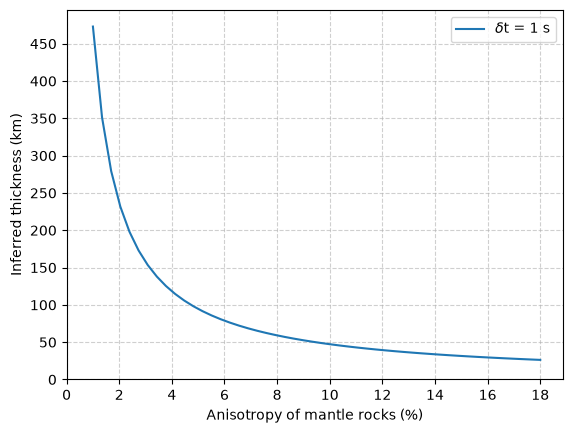

In [15]:
Vs = 4.73  # km/s; given by q2 (for peridotite)
dt = 1  # s; given by q1
anis = np.linspace(1, 18)
L = (dt * Vs) / (anis / 100)

plt.plot(anis, L, label="$\delta$t = 1 s")
# plt.plot(anis, ((dt-0.2) * Vs) / (anis / 100), label="$\delta$t = 0.8 s")
plt.xlabel("Anisotropy of mantle rocks (%)")
plt.ylabel("Inferred thickness (km)")
plt.xticks(np.arange(0, 20, 2))
plt.yticks(np.arange(0, 500, 50))
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.savefig("./attachments/fig1b.png", bbox_inches="tight")
plt.show()

## Q3

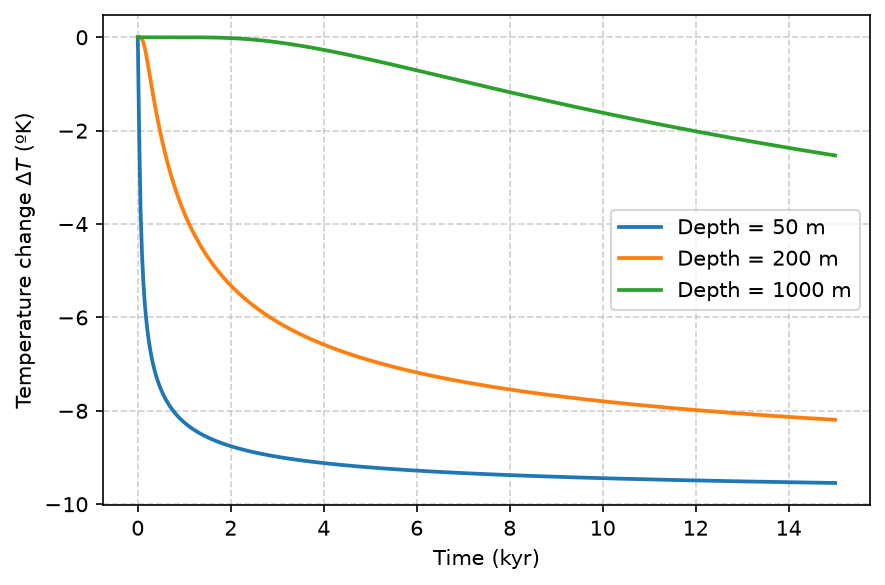

In [46]:
# Physical parameters
depths = np.array([50, 200, 1000])  # Convert km to meters
dT = -10  # K
time_years = np.linspace(1, 15000, 500)  # Time array in years
time_sec = time_years * 365.25 * 24 * 3600  # Convert years to seconds

conductivity = 1.5  # W/(m K)
heat_capacity = 700  # J/(kg K)
rho = 2650  # kg/m^3
thermal_diff = conductivity / (rho * heat_capacity)  # m^2/s

# Plotting
fig, ax = plt.subplots(figsize=(6, 4), dpi=150)

for z in depths:
    # Vectorized calculation using scipy's erf
    T = dT * erfc(z / (2 * np.sqrt(thermal_diff * time_sec)))
    ax.plot(time_years / 1000, T, label=f"Depth = {z} m", linewidth=1.8)

# Styling and formatting
ax.set_xlabel("Time (kyr)", fontsize=10)
ax.set_ylabel("Temperature change $\Delta T$ (ºK)", fontsize=10)
# ax.set_title("1D Transient Heat Diffusion into the Subsurface", fontsize=11, fontweight="bold")
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(frameon=True)

plt.savefig("./attachments/fig3.png", bbox_inches="tight")
plt.tight_layout()
plt.show()

## Q4A

Calculate and plot the temperature at 250~km depth for the half-space cooling model as a function of time.

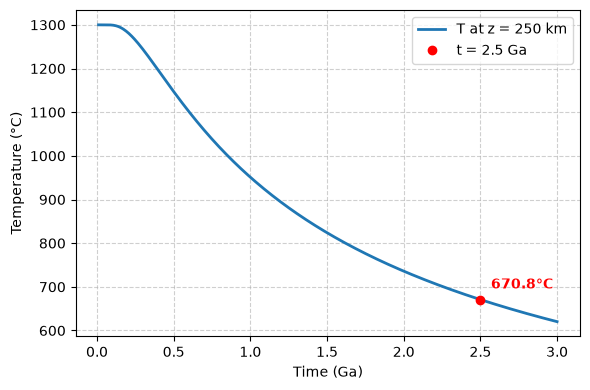

In [78]:
z = 250e3 # Depth in meters (250 km)
Ts = 0.0 # Surface temp (°C)
Tm = 1300.0 # Mantle temp (°C)

conductivity = 1.5  # W/(m K)
heat_capacity = 700  # J/(kg K)
rho = 2650  # kg/m^3
kappa = conductivity / (rho * heat_capacity)  # thermal diffusivity (m^2/s)

t_yr = np.linspace(0.01, 3.0, 500) * 1e9
t_sec = t_yr * 365.25 * 24 * 3600

# half space cooling
T = Ts + (Tm - Ts) * erf(z / (2 * np.sqrt(kappa * t_sec)))

t250 = 1300 * math.erf((250 * 10**3) / (2 * math.sqrt((1.5 / (2650 * 700)) * (2.5 * 10**9 * 365.25 * 24 * 3600))))

plt.figure(figsize=(6, 4))
plt.plot(t_yr / 1e9, T, '-', lw=2, label="T at z = 250 km")
# plt.axvline(2.5, color='r', linestyle='--', label="Craton age (2.5 Ga)")
plt.plot(2.5, t250, color="red", marker="o", label="t = 2.5 Ga", linestyle="")
plt.annotate(
    f" {t250:.1f}°C",  # Text string to display
    (2.5, t250),  # (x, y) point to annotate
    textcoords="offset points",  # Position text relative to point in pixels
    xytext=(4,8),  # Shift text 8px right, 4px down
    fontsize=10,
    fontweight="bold",
    color="red",
)
plt.xlabel("Time (Ga)")
plt.ylabel("Temperature (°C)")
# plt.title("Half-Space Cooling Temperature at 250 km Depth")
plt.grid(True, ls='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("./attachments/fig4a.png", bbox_inches="tight")
plt.show()

In [ ]:
print(f"{t250:.2f}")

670.80
